# Lab 2: Training & Transfer

Before you run anything, guess how much a network pretrained on ImageNet is worth on a small CIFAR-10 task, compared with the same network holding random weights. This lab measures it. You write three routines first: the optimizer update that moves each parameter, the normalization that keeps activations well scaled, and the step that reuses a pretrained backbone for a new task. Then you put them to work in a controlled transfer study.

**What you will do**

1. Apply one momentum-SGD update and watch the velocity build across steps.
2. Turn a pretrained backbone into a transfer model by replacing its head and freezing
   both backbone parameters and BatchNorm running-stat updates.
3. Standardize activations with a batch-normalization forward pass.
4. Design a classifier head to a parameter budget, then run one fine-tuning change.

The "Your task" headings mark the parts you complete. Everything else is provided and ready to run.


## At a glance

| | |
|---|---|
| <font size="3">Stack</font> | <font size="3">PyTorch and torchvision; a GPU runtime is recommended</font> |
| <font size="3">You write</font> | <font size="3">`sgd_step`, `build_transfer_model`, `batchnorm_forward`</font> |
| <font size="3">You submit</font> | <font size="3">C1 to C3 and D1 to D2 for readiness, then answers about your experiment record, your claim and your next experiment</font> |
| <font size="3">GPU runtime</font> | <font size="3">A few minutes of training in quick mode; longer on the full split</font> |


> ### <font color="#A31F34">Big picture</font>
> <hr color="#A31F34">
> A training pipeline is a chain of small, checkable steps. When each step is correct on a fixed probe, the full run is far more likely to behave the way you expect.


## What is graded

The course page has four checkpoints. The first checks that your three functions work. It gives you new inputs, which you put into the Changed cases cell right after your three function tasks, and you enter the three results C1 to C3 it prints, along with D1 and D2 from the final report cell. The other three ask about your experiment record, the claim your runs can support, and the experiment you would run next. Measured accuracy is evidence to interpret, not a number to match, and the official CIFAR-10 test split stays untouched.


> ### <font color="#B45309">Watch out</font>
> <hr color="#B45309">
> Do not treat one validation accuracy as a universal answer. Retain it with the configuration, seed, split, comparison, and caveat that make it interpretable.


In [3]:
from __future__ import annotations

import math
import random
import time
from dataclasses import asdict, dataclass, replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

SEED = 7960
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def reset_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


plt.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.prop_cycle": plt.cycler(
        color=["#A31F34", "#1D4ED8", "#059669", "#B45309", "#7C3AED"]
    ),
})

reset_seed()
print(f"PyTorch {torch.__version__}; device = {DEVICE}")
if DEVICE.type == "cpu":
    print("A free Colab GPU is recommended for the ResNet-18 comparison.")


PyTorch 2.14.1+cpu; device = cpu
A free Colab GPU is recommended for the ResNet-18 comparison.


In [4]:
QUICK_MODE = True
DATA_ROOT = "./data"

TARGET_TRAIN_PER_CLASS = 500
TARGET_VALIDATION_PER_CLASS = 100 if QUICK_MODE else 500
DEFAULT_BATCH_SIZE = 128
TRANSFER_EPOCHS = 2 if QUICK_MODE else 5
TRANSFER_IMAGE_SIZE = 96
NUM_WORKERS = 0 if QUICK_MODE else 2

print(
    f"quick_mode={QUICK_MODE}, target train={10 * TARGET_TRAIN_PER_CLASS:,}, "
    f"validation={10 * TARGET_VALIDATION_PER_CLASS:,}, "
    f"transfer epochs={TRANSFER_EPOCHS}"
)


quick_mode=True, target train=5,000, validation=1,000, transfer epochs=2


## Setup: one fixed target split

Every run uses the same stratified indices and the same validation view.


In [5]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

transfer_train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(TRANSFER_IMAGE_SIZE, scale=(0.75, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)
transfer_eval_transform = transforms.Compose(
    [
        transforms.Resize((TRANSFER_IMAGE_SIZE, TRANSFER_IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

# The original CIFAR-10 server is very slow, so download the identical file from the
# course mirror. torchvision still verifies its MD5 checksum.
datasets.CIFAR10.url = "https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/resolve/v1/cifar-10-python.tar.gz"

split_source = datasets.CIFAR10(DATA_ROOT, train=True, download=True)


def stratified_split(targets, train_per_class, validation_per_class, seed):
    target_tensor = torch.as_tensor(targets)
    generator = torch.Generator().manual_seed(seed)
    train_indices, validation_indices = [], []
    for class_id in range(10):
        class_indices = torch.where(target_tensor == class_id)[0]
        order = torch.randperm(len(class_indices), generator=generator)
        class_indices = class_indices[order]
        needed = train_per_class + validation_per_class
        train_indices.extend(class_indices[:train_per_class].tolist())
        validation_indices.extend(
            class_indices[train_per_class:needed].tolist()
        )
    return sorted(train_indices), sorted(validation_indices)


train_indices, validation_indices = stratified_split(
    split_source.targets,
    TARGET_TRAIN_PER_CLASS,
    TARGET_VALIDATION_PER_CLASS,
    SEED,
)
assert set(train_indices).isdisjoint(validation_indices)

transfer_train_source = datasets.CIFAR10(
    DATA_ROOT, train=True, transform=transfer_train_transform, download=False
)
transfer_eval_source = datasets.CIFAR10(
    DATA_ROOT, train=True, transform=transfer_eval_transform, download=False
)
transfer_train_set = Subset(transfer_train_source, train_indices)
transfer_train_eval_set = Subset(transfer_eval_source, train_indices)
transfer_validation_set = Subset(transfer_eval_source, validation_indices)


def seeded_loader(dataset, *, batch_size, shuffle, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle, drop_last=False,
        num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
        generator=generator,
    )


def trainable_parameter_count(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print("target-training examples:", len(train_indices))
print("validation examples:", len(validation_indices))
print("official CIFAR-10 test split: reserved and not loaded")


100%|██████████| 170M/170M [00:00<00:00, 210MB/s]


target-training examples: 5000
validation examples: 1000
official CIFAR-10 test split: reserved and not loaded


## Your task 1: Write <code>sgd_step</code>


Complete `sgd_step` for a single step of SGD with momentum, the update from Lecture 2.1. Return the updated parameter and velocity. The function must work for plain Python floats and for tensors, so use ordinary arithmetic operators.


<details style="border:1px solid #e5e7eb;border-radius:8px;padding:10px 14px;background:#f9fafb;color:#111827;margin:14px 0;">
<summary style="cursor:pointer;font-weight:600;">How does momentum update the velocity?</summary>
<div style="margin-top:8px;">Each step, scale the old velocity by the momentum factor and add the new gradient. Then move the parameter against the new velocity, scaled by the learning rate. Return <code>(parameter, velocity)</code> in that order.</div>
</details>


In [7]:
def sgd_step(parameter, gradient, velocity, learning_rate, momentum):
    """Return (updated parameter, updated velocity) for one momentum step."""
    velocity = momentum * velocity + gradient
    parameter = parameter - learning_rate * velocity
    return parameter, velocity


In [8]:
sgd_probe_parameter = 2.0
sgd_probe_velocity = 0.0
for _ in range(3):
    sgd_probe_parameter, sgd_probe_velocity = sgd_step(
        sgd_probe_parameter, 0.5, sgd_probe_velocity,
        learning_rate=0.1, momentum=0.9,
    )
sgd_probe_parameter = round(sgd_probe_parameter, 4)
sgd_probe_contract = (
    abs(sgd_probe_parameter - 1.7195) < 1e-6
    and abs(sgd_probe_velocity - 1.355) < 1e-6
)
assert sgd_probe_contract, "Check the momentum accumulation and update order."
print("Task 1 checks passed. Probe parameter after three steps:",
      sgd_probe_parameter)


Task 1 checks passed. Probe parameter after three steps: 1.7195


## Your task 2: Write <code>build_transfer_model</code>


Complete `build_transfer_model` so it (1) reads `backbone.fc.in_features`,
(2) freezes every existing backbone parameter, and (3) replaces `backbone.fc`
with a fresh `nn.Linear(in_features, num_classes)` whose parameters train.
Parameter freezing alone does not freeze BatchNorm buffers. The provided
training code below keeps frozen BatchNorm modules in evaluation mode.


In [10]:
# Task 2
def build_transfer_model(backbone, num_classes):
    """Freeze the backbone and attach a fresh trainable classification head."""
    in_features = backbone.fc.in_features
    for p in backbone.parameters():
        p.requires_grad = False
    backbone.fc = nn.Linear(in_features, num_classes)  # new params train by default
    return backbone

In [11]:
def set_frozen_batchnorm_eval(model: nn.Module) -> None:
    """Stop frozen BatchNorm modules from updating running statistics."""
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()


In [12]:
class ProbeBackbone(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Linear(3, 512)
        self.bn = nn.BatchNorm1d(512)
        self.fc = nn.Linear(512, 1000)

    def forward(self, x):
        return self.fc(torch.relu(self.bn(self.body(x))))


probe_backbone = build_transfer_model(ProbeBackbone(), num_classes=10)
probe_backbone.train()
running_mean_before = probe_backbone.bn.running_mean.clone()
set_frozen_batchnorm_eval(probe_backbone)
with torch.no_grad():
    probe_backbone(torch.ones(4, 3))
transfer_probe_count = trainable_parameter_count(probe_backbone)
transfer_probe_contract = (
    isinstance(probe_backbone.fc, nn.Linear)
    and probe_backbone.fc.in_features == 512
    and probe_backbone.fc.out_features == 10
    and not probe_backbone.body.weight.requires_grad
    and not probe_backbone.bn.training
    and torch.equal(
        running_mean_before, probe_backbone.bn.running_mean
    )
    and transfer_probe_count == 512 * 10 + 10
)
assert transfer_probe_contract, (
    "Only the new 512->10 head should train, and frozen BatchNorm "
    "statistics must remain fixed."
)
assert transfer_probe_count == 5130
print("Task 2 checks passed. Trainable head parameters:", transfer_probe_count)


Task 2 checks passed. Trainable head parameters: 5130


## Your task 3: Write <code>batchnorm_forward</code>


Complete `batchnorm_forward`, the batch-normalization forward pass from Lecture 2.2. Standardize each feature over the batch dimension, then apply the learned scale `gamma` and shift `beta`. Use the population variance (`unbiased=False`), and add `eps` to the variance before taking its square root.


<details style="border:1px solid #e5e7eb;border-radius:8px;padding:10px 14px;background:#f9fafb;color:#111827;margin:14px 0;">
<summary style="cursor:pointer;font-weight:600;">What does standardize mean here?</summary>
<div style="margin-top:8px;">For each feature, subtract its mean over the batch and divide by its standard deviation over the batch. Both statistics are taken over dimension 0.</div>
</details>


In [13]:
# Task 3
def batchnorm_forward(inputs, gamma, beta, eps):
    """Standardize per feature over the batch, then scale and shift."""
    mean = inputs.mean(dim=0, keepdim=True)
    var = inputs.var(dim=0, unbiased=False, keepdim=True)
    return gamma * (inputs - mean) / torch.sqrt(var + eps) + beta


In [14]:
bn_probe_input = torch.tensor([[2.0], [4.0], [4.0], [6.0]])
bn_probe_output = batchnorm_forward(bn_probe_input, gamma=1.0, beta=0.0, eps=0.0)
batchnorm_probe_value = round(bn_probe_output[-1].item(), 5)
batchnorm_probe_contract = (
    abs(bn_probe_output.mean().item()) < 1e-6
    and abs(bn_probe_output.std(unbiased=False).item() - 1.0) < 1e-6
    and abs(batchnorm_probe_value - 1.41421) < 1e-4
)
assert batchnorm_probe_contract, "Output should have mean 0 and unit variance."
print("Task 3 checks passed. Standardized probe activation:", batchnorm_probe_value)


Task 3 checks passed. Standardized probe activation: 1.41421


## Changed cases

The first checkpoint on the course page gives you new inputs for your functions. Replace the values at the top of the next cell with those inputs, run it, and enter C1 to C3 on the course page.

As the cell stands, it uses the same inputs as the fixed probes in your task checks, so you can run it first to see what it prints.


In [15]:
# Replace these values with the inputs from the course page, then run the cell.
C1_START, C1_LEARNING_RATE, C1_MOMENTUM = 2.0, 0.1, 0.9
C1_GRADIENTS = [0.5, 0.5, 0.5]
C2_NUM_CLASSES = 10
C3_INPUTS = torch.tensor([[2.0], [4.0], [4.0], [6.0]])
C3_GAMMA, C3_BETA, C3_EPS = 1.0, 0.0, 0.0
C3_ROW, C3_FEATURE = 3, 0

parameter, velocity = C1_START, 0.0
for gradient in C1_GRADIENTS:
    parameter, velocity = sgd_step(parameter, gradient, velocity, C1_LEARNING_RATE, C1_MOMENTUM)
c2 = trainable_parameter_count(build_transfer_model(ProbeBackbone(), num_classes=C2_NUM_CLASSES))
c3 = batchnorm_forward(C3_INPUTS, C3_GAMMA, C3_BETA, C3_EPS)[C3_ROW, C3_FEATURE].item()
print(f"C1: {parameter:.4f}")
print(f"C2: {c2}")
print(f"C3: {c3:.5f}")


C1: 1.7195
C2: 5130
C3: 1.41421


## Provided: training and transfer

The code below assembles a ResNet-18 from a configuration, trains only the
parameters you leave unfrozen, and records complete histories. `assemble_model` calls your
`build_transfer_model` whenever the head is a single linear layer.


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 414MB/s]


        transfer control | epoch 1/2 | val acc 74.20%
        transfer control | epoch 2/2 | val acc 77.30%


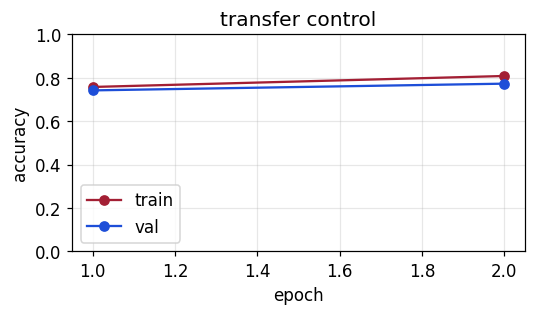

In [16]:
@dataclass(frozen=True)
class TransferExperiment:
    use_pretrained: bool = True
    head_hidden: int = 0
    freeze_backbone: bool = True
    weight_decay: float = 0.0
    use_augmentation: bool = False
    learning_rate: float = 1e-3
    batch_size: int = DEFAULT_BATCH_SIZE
    epochs: int = TRANSFER_EPOCHS
    seed: int = SEED


def changed_config_fields(reference, candidate):
    reference_fields = asdict(reference)
    candidate_fields = asdict(candidate)
    return {
        name for name in reference_fields
        if reference_fields[name] != candidate_fields[name]
    }


def history_is_complete(record):
    history = record["history"]
    epochs = record["config"]["epochs"]
    return all(
        len(history[metric]) == epochs
        for metric in (
            "train_loss", "train_accuracy",
            "validation_loss", "validation_accuracy",
        )
    )


def build_head(in_features, head_hidden, num_classes):
    # The classifier head on top of the frozen 512-d features: one linear layer,
    # or a two-layer MLP once head_hidden > 0 (your task-4 design).
    if head_hidden <= 0:
        return nn.Linear(in_features, num_classes)
    return nn.Sequential(
        nn.Linear(in_features, head_hidden),
        nn.ReLU(),
        nn.Linear(head_hidden, num_classes),
    )


def assemble_model(config):
    # Build the ResNet-18 a config calls for: ImageNet-pretrained or random
    # features, then attach the head and set which parameters train.
    reset_seed(config.seed)
    weights = (
        models.ResNet18_Weights.IMAGENET1K_V1
        if config.use_pretrained else None
    )
    backbone = models.resnet18(weights=weights)
    if config.head_hidden <= 0:
        # Linear head: your build_transfer_model freezes the backbone and swaps
        # in a fresh 512->10 layer; unfreeze again for full fine-tuning.
        backbone = build_transfer_model(backbone, num_classes=10)
        if not config.freeze_backbone:
            for parameter in backbone.parameters():
                parameter.requires_grad = True
    else:
        # MLP head: freeze (or not) the backbone, then attach your wider head.
        in_features = backbone.fc.in_features
        for parameter in backbone.parameters():
            parameter.requires_grad = not config.freeze_backbone
        backbone.fc = build_head(in_features, config.head_hidden, 10)
    return backbone


@torch.no_grad()
def evaluate_classifier(model, loader):
    # Mean loss and accuracy over a loader: sum across all examples, divide once.
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total_loss = total_correct = total_examples = 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        logits = model(images)
        total_loss += loss_fn(logits, labels).item()
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += labels.numel()
    return total_loss / total_examples, total_correct / total_examples


def plot_history(record):
    history = record["history"]
    epochs = np.arange(1, len(history["train_accuracy"]) + 1)
    plt.figure(figsize=(5, 3))
    plt.plot(epochs, history["train_accuracy"], marker="o", label="train")
    plt.plot(epochs, history["validation_accuracy"], marker="o", label="val")
    plt.title(record["label"]); plt.xlabel("epoch"); plt.ylabel("accuracy")
    plt.ylim(0, 1); plt.legend(); plt.tight_layout(); plt.show()


def run_transfer_experiment(label, config):
    # Train one configuration end to end and return a record with its config (as
    # a dict) and the full per-epoch history that the report cell later checks.
    model = assemble_model(config).to(DEVICE)
    # Augmented view only when the config asks for it; evaluation view otherwise.
    train_source = (
        transfer_train_set if config.use_augmentation
        else transfer_train_eval_set
    )
    fit_loader = seeded_loader(
        train_source, batch_size=config.batch_size, shuffle=True,
        seed=config.seed,
    )
    train_eval_loader = seeded_loader(
        transfer_train_eval_set, batch_size=config.batch_size,
        shuffle=False, seed=config.seed,
    )
    validation_loader = seeded_loader(
        transfer_validation_set, batch_size=config.batch_size,
        shuffle=False, seed=config.seed,
    )
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(
        trainable, lr=config.learning_rate, weight_decay=config.weight_decay
    )
    loss_fn = nn.CrossEntropyLoss()
    history = {
        "train_loss": [], "train_accuracy": [],
        "validation_loss": [], "validation_accuracy": [],
    }
    for epoch in range(1, config.epochs + 1):
        model.train()
        # model.train() recursively re-enables BatchNorm updates. Re-apply
        # evaluation mode to frozen BatchNorm modules every epoch so neither
        # affine parameters nor running statistics adapt in a frozen backbone.
        if config.freeze_backbone:
            set_frozen_batchnorm_eval(model)
        for images, labels in fit_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(images), labels)
            loss.backward()
            optimizer.step()
        train_loss, train_accuracy = evaluate_classifier(model, train_eval_loader)
        validation_loss, validation_accuracy = evaluate_classifier(
            model, validation_loader
        )
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)
        print(
            f"{label:>24} | epoch {epoch}/{config.epochs} | "
            f"val acc {validation_accuracy:.2%}"
        )
    record = {"label": label, "config": asdict(config), "history": history}
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return record


control_config = TransferExperiment()
control_result = run_transfer_experiment("transfer control", control_config)
plot_history(control_result)


## Your task 4: Design a classifier head


Choose `head_hidden` so that a two-layer head on top of the frozen 512-d features has 20,000 to 120,000 trainable parameters. Work the count out yourself before you pick a value. The cell below prints it and checks the range.


In [18]:
# STUDENT TASK 4: pick a positive head_hidden inside the budget.
import torch.nn as nn
from dataclasses import replace

head_hidden = 64  # 523*64 + 10 = 33,482 params (allowed range: 20k-120k)


# Same definitions as the provided cell, repeated here so this cell is self-contained.
def build_head(in_features, head_hidden, num_classes):
    if head_hidden <= 0:
        return nn.Linear(in_features, num_classes)
    return nn.Sequential(
        nn.Linear(in_features, head_hidden),
        nn.ReLU(),
        nn.Linear(head_hidden, num_classes),
    )


def trainable_parameter_count(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


learner_head = build_head(512, head_hidden, num_classes=10)
learner_head_parameter_count = trainable_parameter_count(learner_head)
learner_parameter_count = learner_head_parameter_count

expected = 512 * head_hidden + head_hidden + head_hidden * 10 + 10
print(f"head_hidden = {head_hidden}")
print(f"counted parameters  = {learner_parameter_count:,}")
print(f"expected parameters = {expected:,}")

if not (20_000 <= learner_parameter_count <= 120_000):
    raise ValueError(
        f"Head has {learner_parameter_count:,} parameters; "
        "choose head_hidden so it has 20,000-120,000."
    )

learner_config = replace(control_config, head_hidden=head_hidden)
print(f"learner head parameters: {learner_parameter_count:,}")

head_hidden = 64
counted parameters  = 33,482
expected parameters = 33,482
learner head parameters: 33,482


frozen random-feature control | epoch 1/2 | val acc 10.70%
frozen random-feature control | epoch 2/2 | val acc 16.40%
     learner head design | epoch 1/2 | val acc 74.00%
     learner head design | epoch 2/2 | val acc 78.90%


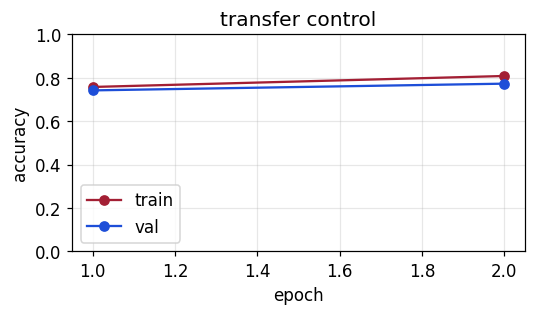

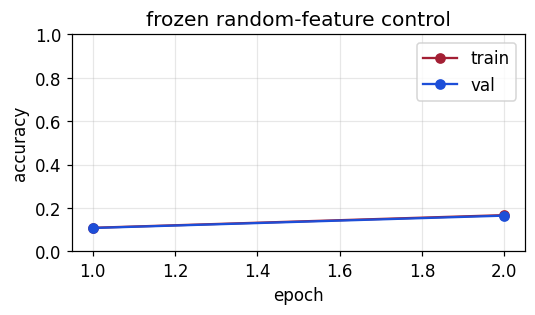

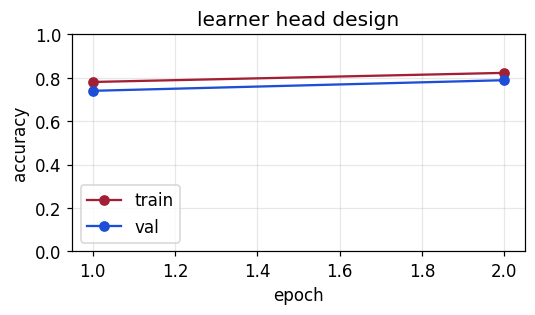

In [19]:
# This comparator keeps its random backbone frozen, so only its head trains.
scratch_config = replace(control_config, use_pretrained=False)
scratch_result = run_transfer_experiment(
    "frozen random-feature control", scratch_config
)
learner_result = run_transfer_experiment("learner head design", learner_config)
for record in (control_result, scratch_result, learner_result):
    plot_history(record)


## Your task 5: Choose one fine-tuning intervention


Predict what will change, then choose exactly one intervention relative to the
transfer control: unfreeze the backbone (`full_finetune`), add training
augmentation (`augmentation`), or add weight decay (`weight_decay`). The check below
allows exactly one field to differ from the control.


In [20]:
# STUDENT TASK 5: choose "full_finetune", "augmentation", or "weight_decay".
FINE_TUNE_CHOICE = "full_finetune"

TREATMENT_OVERRIDES = {
    "full_finetune": {"freeze_backbone": False},
    "augmentation": {"use_augmentation": True},
    "weight_decay": {"weight_decay": 1e-4},
}
TREATMENT_FIELDS = {
    "full_finetune": "freeze_backbone",
    "augmentation": "use_augmentation",
    "weight_decay": "weight_decay",
}
TREATMENT_LABELS = {
    "full_finetune": "chosen treatment: full fine-tune",
    "augmentation": "chosen treatment: augmentation",
    "weight_decay": "chosen treatment: weight decay",
}
if FINE_TUNE_CHOICE not in TREATMENT_OVERRIDES:
    raise ValueError("Choose full_finetune, augmentation, or weight_decay.")
treatment_config = replace(
    control_config, **TREATMENT_OVERRIDES[FINE_TUNE_CHOICE]
)
assert changed_config_fields(control_config, treatment_config) == {
    TREATMENT_FIELDS[FINE_TUNE_CHOICE]
}


chosen treatment: full fine-tune | epoch 1/2 | val acc 73.80%
chosen treatment: full fine-tune | epoch 2/2 | val acc 76.30%


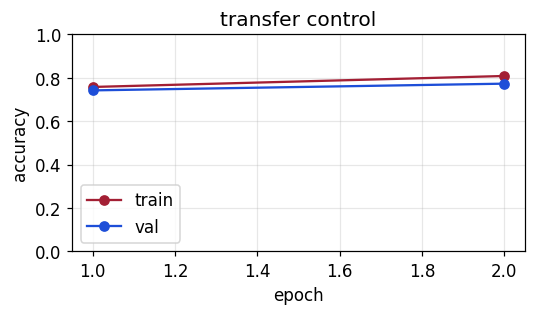

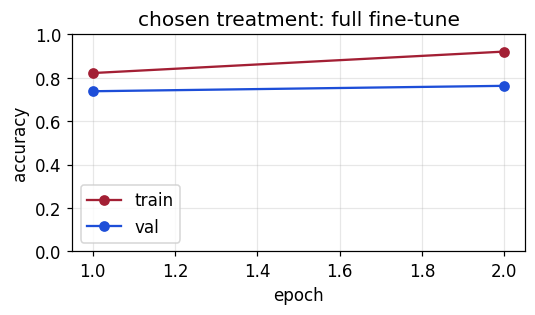

In [21]:
treatment_result = run_transfer_experiment(
    TREATMENT_LABELS[FINE_TUNE_CHOICE], treatment_config
)
for record in (control_result, treatment_result):
    plot_history(record)


## Build your experiment record

Run the next cell to capture the configurations and final train and validation metrics for all four runs. Keep this table with your notebook. Then write four short statements beneath it:

- **Claim:** one statement about a comparison in the table that the numbers can support.
- **Evidence:** the named rows, metric, and quantitative difference supporting it.
- **Caveat:** one reason the observed difference might not generalize.
- **Next experiment:** a one-factor or matched comparison that could challenge the claim.


In [22]:
evidence_rows = []
for record in (
    control_result, scratch_result, learner_result, treatment_result
):
    history = record["history"]
    evidence_rows.append({
        "run": record["label"],
        "seed": record["config"]["seed"],
        "pretrained": record["config"]["use_pretrained"],
        "backbone_frozen": record["config"]["freeze_backbone"],
        "batchnorm_mode_when_frozen": (
            "eval" if record["config"]["freeze_backbone"] else "train"
        ),
        "train_accuracy_final": history["train_accuracy"][-1],
        "validation_accuracy_final": history["validation_accuracy"][-1],
        "validation_loss_final": history["validation_loss"][-1],
    })

evidence_table = pd.DataFrame(evidence_rows)
display(evidence_table)
print("Keep this table with your claim, evidence, caveat, and next experiment.")


,run,seed,pretrained,backbone_frozen,batchnorm_mode_when_frozen,train_accuracy_final,validation_accuracy_final,validation_loss_final
0,transfer control,7960,True,True,eval,0.8084,0.773,0.689296
1,frozen random-feature control,7960,False,True,eval,0.1664,0.164,2.251217
2,learner head design,7960,True,True,eval,0.8228,0.789,0.641894
3,chosen treatment: full fine-tune,7960,True,False,train,0.9210,0.763,0.721459


Keep this table with your claim, evidence, caveat, and next experiment.


## Report values

Run the cell below after finishing all five tasks and all four training runs. It prints R1 to R5 and D1 to D2. R1 to R3 repeat the fixed probes from your task checks, R4 is your head design's parameter count, and R5 confirms the workflow ran as intended. Keep those with your evidence table. D1 and D2 go into the first checkpoint on the course page, together with C1 to C3 from the Changed cases cell.

**Before you submit**

- [ ] I entered C1 to C3 from the Changed cases cell, and D1 and D2 from this report cell.
- [ ] I kept the configuration-and-metric evidence table.
- [ ] I wrote a claim, the evidence for it, a caveat, and a next experiment.
- [ ] I left the official test split untouched.


In [23]:
run_config_pairs = (
    (control_result, control_config),
    (scratch_result, scratch_config),
    (learner_result, learner_config),
    (treatment_result, treatment_config),
)

workflow_contract = int(
    set(train_indices).isdisjoint(validation_indices)
    and len({record["label"] for record, _ in run_config_pairs}) == 4
    and all(
        record["config"] == asdict(config)
        for record, config in run_config_pairs
    )
    and all(history_is_complete(record) for record, _ in run_config_pairs)
    and changed_config_fields(control_config, scratch_config)
        == {"use_pretrained"}
    and changed_config_fields(control_config, learner_config)
        == {"head_hidden"}
    and changed_config_fields(control_config, treatment_config)
        == {TREATMENT_FIELDS[FINE_TUNE_CHOICE]}
    and learner_parameter_count == learner_head_parameter_count
    and 20_000 <= learner_parameter_count <= 120_000
)

probe_sgd_parameter = round(sgd_probe_parameter, 4) if sgd_probe_contract else -1.0
probe_transfer_parameters = (
    transfer_probe_count if transfer_probe_contract else -1
)
probe_batchnorm_value = (
    round(batchnorm_probe_value, 5) if batchnorm_probe_contract else -1.0
)

# Data probes. These read the CIFAR bytes in the order the dataset file
# stores them, so a notebook that was never run cannot produce them.
# They deliberately avoid the seeded split. That ordering comes from
# PyTorch's RNG, which is not guaranteed stable across releases, and these
# two numbers have to mean the same thing in every learner's session.
PROBE_OFFSET = 10
split_probe_labels = sum(
    int(split_source.targets[index])
    for index in range(PROBE_OFFSET, PROBE_OFFSET + 10)
)
split_probe_pixel_mean = round(
    float(np.asarray(split_source[PROBE_OFFSET][0], dtype=float).mean()),
    4,
)

report_values = {
    "R1: momentum-SGD probe parameter after three steps": probe_sgd_parameter,
    "R2: transfer head trainable parameters (frozen backbone)": probe_transfer_parameters,
    "R3: batch-normalized probe activation": probe_batchnorm_value,
    "R4: learner-designed head parameter count": learner_parameter_count,
    "R5: experimental workflow contract": workflow_contract,
    "D1: ten CIFAR labels from the probe offset, summed": split_probe_labels,
    "D2: mean pixel value of the probe-offset image": split_probe_pixel_mean,
}
assert probe_sgd_parameter == 1.7195
assert probe_transfer_parameters == 5130
assert probe_batchnorm_value == 1.41421
assert 20_000 <= learner_parameter_count <= 120_000
assert workflow_contract == 1

print("LAB 2 REPORT VALUES")
for label, value in report_values.items():
    print(f"{label}: {value}")


LAB 2 REPORT VALUES
R1: momentum-SGD probe parameter after three steps: 1.7195
R2: transfer head trainable parameters (frozen backbone): 5130
R3: batch-normalized probe activation: 1.41421
R4: learner-designed head parameter count: 33482
R5: experimental workflow contract: 1
D1: ten CIFAR labels from the probe offset, summed: 58
D2: mean pixel value of the probe-offset image: 73.778
